## 1. データを読み、日時を直す

In [1]:
import pandas as pd

meta = pd.read_csv("data/metadata.csv")
print(meta.shape)
print(meta.columns.tolist())
print(meta.head())
print(meta["type"].value_counts())
print("電池の数:", meta["battery_id"].nunique())

(7565, 10)
['type', 'start_time', 'ambient_temperature', 'battery_id', 'test_id', 'uid', 'filename', 'Capacity', 'Re', 'Rct']
        type                                         start_time  \
0  discharge  [2010.       7.      21.      15.       0.    ...   
1  impedance  [2010.       7.      21.      16.      53.    ...   
2     charge  [2010.       7.      21.      17.      25.    ...   
3  impedance                    [2010    7   21   20   31    5]   
4  discharge  [2.0100e+03 7.0000e+00 2.1000e+01 2.1000e+01 2...   

   ambient_temperature battery_id  test_id  uid   filename  \
0                    4      B0047        0    1  00001.csv   
1                   24      B0047        1    2  00002.csv   
2                    4      B0047        2    3  00003.csv   
3                   24      B0047        3    4  00004.csv   
4                    4      B0047        4    5  00005.csv   

             Capacity                   Re                  Rct  
0  1.6743047446975208           

In [2]:
import re #正規表現

def parse_time(s):
    nums = [float(x) for x in re.findall(r"[-+]?\d+\.?\d*(?:[eE][-+]?\d+)?", s)]
    y, mo, d, h, mi, sec = nums[:6]
    return pd.Timestamp(int(y), int(mo), int(d), int(h), int(mi)) + pd.to_timedelta(sec, unit="s")

meta["time"] = meta["start_time"].apply(parse_time)
for c in ["Capacity", "Re", "Rct"]:
    meta[c] = pd.to_numeric(meta[c], errors="coerce")

print(meta[["time", "Capacity", "Re", "Rct"]].describe())
print(meta.groupby("battery_id")["type"].value_counts().unstack())
print(meta.groupby("type")["ambient_temperature"].value_counts())

                                time     Capacity            Re           Rct
count                           7565  2769.000000  1.947000e+03  1.947000e+03
mean   2009-08-14 03:15:31.312608768     1.326543 -4.976500e+11  1.055903e+12
min       2008-04-02 13:08:17.921000     0.000000 -9.689245e+14 -2.091081e+02
25%    2008-07-11 18:25:27.592999936     1.150286  5.782157e-02  8.155754e-02
50%    2009-08-02 09:10:15.046000128     1.428065  7.255344e-02  1.014191e-01
75%    2010-06-30 09:21:28.343000064     1.673645  9.229960e-02  1.565123e-01
max       2010-09-30 15:32:33.078000     2.640149  4.482291e+02  2.055843e+15
std                              NaN     0.472517  2.195872e+13  4.659154e+13
type        charge  discharge  impedance
battery_id                              
B0005          170        168        278
B0006          170        168        278
B0007          170        168        278
B0018          134        132         53
B0025           31         28         21
B0026      

## 2. おかしな値を数える

In [3]:
imp = meta[meta["type"] == "impedance"]
print("インピーダンス:", len(imp),
      " Re異常:", (~imp["Re"].between(0, 1)).sum(),
      " Rct異常:", (~imp["Rct"].between(0, 1)).sum())

dis = meta[meta["type"] == "discharge"].sort_values("time")
print("容量0以下:", (dis["Capacity"] <= 0).sum(), " 2Ah超:", (dis["Capacity"] > 2).sum())

summary = dis.groupby("battery_id").agg(
    放電温度=("ambient_temperature", lambda s: sorted(s.unique())),
    最初の容量=("Capacity", "first"),
    最小容量=("Capacity", "min"),
    件数=("Capacity", "size"),
)
print(summary)


imp = meta[meta["type"] == "impedance"]
print("インピーダンス:", len(imp),
      "Re異常:", len(imp))

インピーダンス: 1956  Re異常: 23  Rct異常: 23
容量0以下: 19  2Ah超: 11
                放電温度     最初の容量      最小容量   件数
battery_id                                   
B0005           [24]  1.856487  1.287453  168
B0006           [24]  2.035338  1.153818  168
B0007           [24]  1.891052  1.400455  168
B0018           [24]  1.855005  1.341051  132
B0025           [24]  1.847011  1.767789   28
B0026           [24]  1.813250  1.386337   28
B0027           [24]  1.823308  1.770093   28
B0028           [24]  1.804685  1.717234   28
B0029           [43]  1.697507  1.612080   40
B0030           [43]  1.656071  1.562780   40
B0031           [43]  1.666675  1.666675   40
B0032           [43]  1.704864  1.635800   40
B0033           [24]  0.068426  0.068426  197
B0034           [24]  0.745930  0.745930  197
B0036           [24]  1.001983  1.001983  197
B0038       [24, 44]  0.898057  0.898057   47
B0039       [24, 44]  0.119038  0.119038   47
B0040       [24, 44]  0.673463  0.425812   47
B0041            [4]  0.0

## 3. 本命8本で、内部抵抗と直前の容量を組にする

In [4]:
CORE = ["B0005", "B0006", "B0007", "B0018", "B0025", "B0026", "B0027", "B0028"]
m = meta[meta["battery_id"].isin(CORE)]

# インピーダンス測定（おかしな値は除く）
imp = m[(m["type"] == "impedance") & m["Re"].between(0, 1) & m["Rct"].between(0, 1)]
imp = imp[["battery_id", "time", "Re", "Rct"]].sort_values("time")

# 放電（容量0などは除く）
dis = m[(m["type"] == "discharge") & m["Capacity"].between(0.1, 2.5)]
dis = dis[["battery_id", "time", "Capacity"]].rename(columns={"time": "dis_time"}).sort_values("dis_time")

# 各インピーダンス測定に「同じ電池の、直前の放電」をくっつける
df = pd.merge_asof(imp, dis, left_on="time", right_on="dis_time",
                   by="battery_id", direction="backward")

df["gap_h"] = (df["time"] - df["dis_time"]).dt.total_seconds() / 3600
df["SOH"] = df["Capacity"] / 2.0
df["劣化"] = (df["SOH"] < 0.8).astype(int)

print("件数:", len(df), " 容量がつかなかった:", df["Capacity"].isna().sum())
print(df["gap_h"].describe())
print(df.groupby("battery_id").agg(件数=("SOH", "size"), 劣化=("劣化", "sum"), SOH最小=("SOH", "min")))

件数: 971  容量がつかなかった: 9
count    962.000000
mean       4.154990
std       17.791672
min        0.804991
25%        0.881675
50%        1.880352
75%        4.387114
max      310.148438
Name: gap_h, dtype: float64
             件数   劣化     SOH最小
battery_id                    
B0005       278  173  0.643726
B0006       278  196  0.576909
B0007       278  147  0.700228
B0018        53   26  0.673115
B0025        21    0  0.883895
B0026        21    2  0.693169
B0027        21    0  0.885046
B0028        21    0  0.858617


In [5]:
# ① 間の時間が長い組がどれくらいあるか見る
for h in [6, 12, 24, 48]:
    print(f"{h}時間超:", (df["gap_h"] > h).sum(), "件")

6時間超: 22 件
12時間超: 18 件
24時間超: 14 件
48時間超: 7 件


In [6]:
# ② 容量がつかなかった行と、間が長すぎる行を捨てる
LIMIT = 12    # ①を見て、自分で決める（単位は時間）

df2 = df.dropna(subset=["Capacity"])          # 容量が空の行を捨てる
df2 = df2[df2["gap_h"] <= LIMIT]           # 間が LIMIT 以下の行だけ残す

print("残った件数:", len(df2))
print("劣化:", df2["劣化"].sum(), " 正常:", (df2["劣化"] == 0).sum())

残った件数: 944
劣化: 538  正常: 406


## 4. 内部抵抗と SOH の散布図

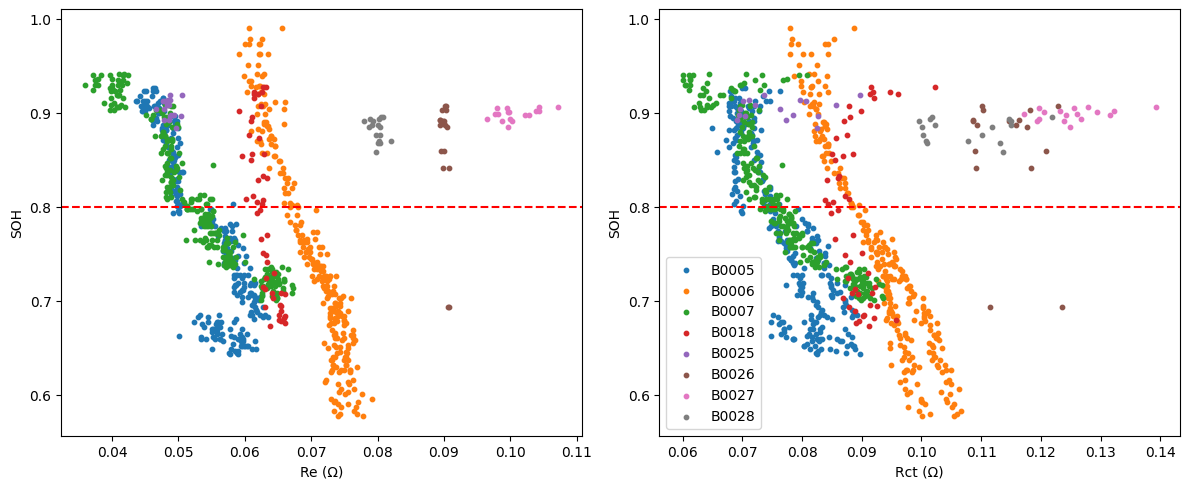

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))   # 横に2つ並べたグラフ

for b, g in df2.groupby("battery_id"):            # 電池ごとに色を変えて描く
    axes[0].scatter(g["Re"], g["SOH"], s=10, label=b)   # 左：Re と SOH
    axes[1].scatter(g["Rct"], g["SOH"], s=10, label=b)   # 右：Rct と SOH

for ax, name in zip(axes, ["Re (Ω)", "Rct (Ω)"]):
    ax.axhline(0.8, color="red", linestyle="--")   # 劣化の線（SOH 80%）
    ax.set_xlabel(name)
    ax.set_ylabel("SOH")

axes[1].legend()
plt.tight_layout()
plt.show()

## 5. 最初からの倍率（Re_ratio）を作る

In [8]:
df2 = df2.sort_values(["battery_id","time"])
df2["Re_first"] = df2.groupby("battery_id")["Re"].transform("first")
df2["Re_ratio"] = df2["Re"] / df2["Re_first"]

print(df2[["battery_id","time","Re","Re_first","Re_ratio"]].head(10))

   battery_id                    time        Re  Re_first  Re_ratio
5       B0005 2008-04-18 22:39:16.312  0.046687  0.046687  1.000000
8       B0005 2008-04-19 02:14:27.015  0.044843  0.046687  0.960512
10      B0005 2008-04-19 03:57:24.187  0.046195  0.046687  0.989455
13      B0005 2008-04-19 07:32:33.656  0.045101  0.046687  0.966032
16      B0005 2008-04-19 09:15:10.453  0.045991  0.046687  0.985087
19      B0005 2008-04-19 12:47:00.421  0.044172  0.046687  0.946132
21      B0005 2008-04-19 14:28:58.984  0.045217  0.046687  0.968516
26      B0005 2008-04-19 18:12:47.531  0.043787  0.046687  0.937876
27      B0005 2008-04-19 19:55:05.296  0.044910  0.046687  0.961937
32      B0005 2008-04-19 23:27:13.343  0.044639  0.046687  0.956140


## 6. Re_ratio と SOH、初めて 0.8 を切った値

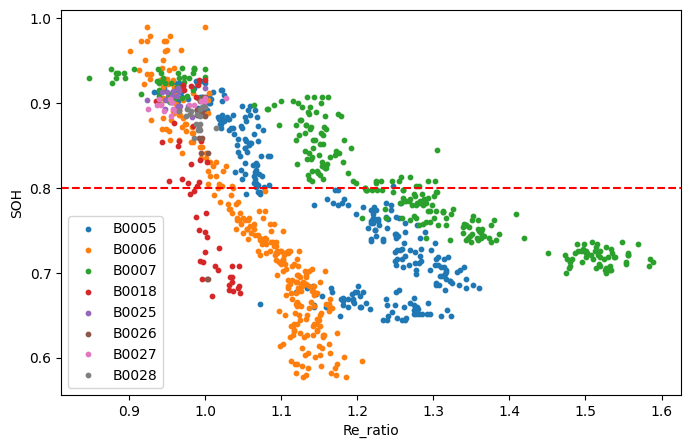

In [9]:
main8 = ["B0005", "B0006", "B0007", "B0018",
         "B0025", "B0026", "B0027", "B0028"]

d = df2[df2["battery_id"].isin(main8)]

plt.figure(figsize=(8,5))
for bid, g in d.groupby("battery_id"):
    plt.scatter(g["Re_ratio"],g["SOH"],s=10,label=bid)

plt.axhline(0.8,color="red",linestyle="--")
plt.xlabel("Re_ratio")
plt.ylabel("SOH")
plt.legend()
plt.show()


In [10]:
d = d.sort_values(["battery_id","time"])

below = d[d["SOH"]<0.8]

first_cross = below.groupby("battery_id").first()
first_cross[["Re_ratio","SOH"]]

,Re_ratio,SOH
battery_id,,
B0005,1.072305,0.795185
B0006,1.037046,0.799486
B0007,1.218845,0.797959
B0018,0.986088,0.796048
B0026,1.002791,0.693169


## 7. B0026 の外れ値を確かめて除く

In [11]:
b26 = below[below["battery_id"]=="B0026"]
print(len(b26))
b26[["time","SOH","Re_ratio"]]

2


,time,SOH,Re_ratio
904,2009-02-18 12:41:09.765,0.693169,1.002791
907,2009-02-18 16:17:23.281,0.693169,1.003819


In [12]:
d26 = d[d["battery_id"] == "B0026"]
near = d26[(d26["time"] >= "2009-02-17") & (d26["time"] <= "2009-02-19")]
near[["time","SOH","Re_ratio"]]

,time,SOH,Re_ratio
904,2009-02-18 12:41:09.765,0.693169,1.002791
907,2009-02-18 16:17:23.281,0.693169,1.003819


In [13]:
print(len(d26))
d26[["time","SOH","Re_ratio"]]

17


,time,SOH,Re_ratio
898,2009-02-14 20:28:47.968,0.907146,1.000000
901,2009-02-15 00:05:09.796,0.907146,0.997613
904,2009-02-18 12:41:09.765,0.693169,1.002791
907,2009-02-18 16:17:23.281,0.693169,1.003819
911,2009-02-19 12:18:04.484,0.902466,0.993264
918,2009-02-19 15:50:59.703,0.902466,0.998491
921,2009-02-20 11:37:00.562,0.858840,0.995814
924,2009-02-20 15:11:41.671,0.858840,0.991482
927,2009-02-21 12:34:32.359,0.892110,0.989856
934,2009-02-21 16:10:34.171,0.892110,0.989525


In [14]:
d = d.drop(index=[904,907])
print(len(d))
print(len(d[(d["battery_id"] == "B0026") & (d["SOH"] < 0.8)]))

942
0


In [15]:
d = d.sort_values(["battery_id","time"])

below = d[d["SOH"]<0.8]

first_cross = below.groupby("battery_id").first()
first_cross[["Re_ratio","SOH"]]

,Re_ratio,SOH
battery_id,,
B0005,1.072305,0.795185
B0006,1.037046,0.799486
B0007,1.218845,0.797959
B0018,0.986088,0.796048


## 8. 線を手で試す

In [16]:
LINE = 1.0
d["判定"] = (d["Re_ratio"] >= LINE).astype(int)
pd.crosstab(d["劣化"],d["判定"])

判定,0,1
劣化,,
0,213,193
1,8,528


In [17]:
print(d.columns)
print("---------------------")
print(d.head())

Index(['battery_id', 'time', 'Re', 'Rct', 'dis_time', 'Capacity', 'gap_h',
       'SOH', '劣化', 'Re_first', 'Re_ratio', '判定'],
      dtype='object')
---------------------
   battery_id                    time        Re       Rct  \
5       B0005 2008-04-18 22:39:16.312  0.046687  0.076275   
8       B0005 2008-04-19 02:14:27.015  0.044843  0.067972   
10      B0005 2008-04-19 03:57:24.187  0.046195  0.074534   
13      B0005 2008-04-19 07:32:33.656  0.045101  0.068528   
16      B0005 2008-04-19 09:15:10.453  0.045991  0.073427   

                  dis_time  Capacity     gap_h       SOH  劣化  Re_first  \
5  2008-04-18 21:10:19.796  1.847026  1.482366  0.923513   0  0.046687   
8  2008-04-18 21:10:19.796  1.847026  5.068672  0.923513   0  0.046687   
10 2008-04-19 02:29:09.000  1.847417  1.470885  0.923709   0  0.046687   
13 2008-04-19 02:29:09.000  1.847417  5.056849  0.923709   0  0.046687   
16 2008-04-19 07:47:15.703  1.836177  1.465208  0.918089   0  0.046687   

    Re_ratio  判定  

## 9. 線1本を電池単位で検証（Re_ratio・Re・Rct）

In [18]:
for bid in main8:
    train_cross = first_cross.drop(bid, errors="ignore")
    LINE = train_cross["Re_ratio"].min()

    test = d[d["battery_id"] == bid]
    pred = (test["Re_ratio"] >= LINE).astype(int)

    miss = ((test["劣化"] == 1) & (pred == 0)).sum()
    over = ((test["劣化"] == 0) & (pred == 1)).sum()
    print("試験役",bid,"線",round(LINE,3), "見逃し",miss,"言い過ぎ",over,"件数",len(test))
    

試験役 B0005 線 0.986 見逃し 0 言い過ぎ 87 件数 275
試験役 B0006 線 0.986 見逃し 0 言い過ぎ 21 件数 275
試験役 B0007 線 0.986 見逃し 0 言い過ぎ 88 件数 275
試験役 B0018 線 1.037 見逃し 22 言い過ぎ 0 件数 51
試験役 B0025 線 0.986 見逃し 0 言い過ぎ 2 件数 17
試験役 B0026 線 0.986 見逃し 0 言い過ぎ 15 件数 15
試験役 B0027 線 0.986 見逃し 0 言い過ぎ 4 件数 17
試験役 B0028 線 0.986 見逃し 0 言い過ぎ 12 件数 17


In [19]:
for bid in main8:
    train_cross = first_cross.drop(bid, errors="ignore")
    LINE = train_cross["Re"].min()

    test = d[d["battery_id"] == bid]
    pred = (test["Re"] >= LINE).astype(int)

    miss = ((test["劣化"] == 1) & (pred == 0)).sum()
    over = ((test["劣化"] == 0) & (pred == 1)).sum()
    print("試験役",bid,"線",round(LINE,3), "見逃し",miss,"言い過ぎ",over,"件数",len(test))

試験役 B0005 線 0.052 見逃し 5 言い過ぎ 1 件数 275
試験役 B0006 線 0.05 見逃し 0 言い過ぎ 81 件数 275
試験役 B0007 線 0.05 見逃し 0 言い過ぎ 19 件数 275
試験役 B0018 線 0.05 見逃し 0 言い過ぎ 25 件数 51
試験役 B0025 線 0.05 見逃し 0 言い過ぎ 2 件数 17
試験役 B0026 線 0.05 見逃し 0 言い過ぎ 15 件数 15
試験役 B0027 線 0.05 見逃し 0 言い過ぎ 17 件数 17
試験役 B0028 線 0.05 見逃し 0 言い過ぎ 17 件数 17


In [20]:
for bid in main8:
    train_cross = first_cross.drop(bid, errors="ignore")
    LINE = train_cross["Rct"].min()

    test = d[d["battery_id"] == bid]
    pred = (test["Rct"] >= LINE).astype(int)

    miss = ((test["劣化"] == 1) & (pred == 0)).sum()
    over = ((test["劣化"] == 0) & (pred == 1)).sum()
    print("試験役",bid,"線",round(LINE,3), "見逃し",miss,"言い過ぎ",over,"件数",len(test))    

試験役 B0005 線 0.075 見逃し 3 言い過ぎ 7 件数 275
試験役 B0006 線 0.07 見逃し 0 言い過ぎ 81 件数 275
試験役 B0007 線 0.07 見逃し 0 言い過ぎ 85 件数 275
試験役 B0018 線 0.07 見逃し 0 言い過ぎ 25 件数 51
試験役 B0025 線 0.07 見逃し 0 言い過ぎ 14 件数 17
試験役 B0026 線 0.07 見逃し 0 言い過ぎ 15 件数 15
試験役 B0027 線 0.07 見逃し 0 言い過ぎ 17 件数 17
試験役 B0028 線 0.07 見逃し 0 言い過ぎ 17 件数 17


## 10. 判定の関数（judge.py）

In [21]:
LINE = 0.986

def judge(re_first, re_now):
    ratio = re_now/re_first
    if ratio >= LINE:
        return "劣化"
    else:
        return "元気"

print(judge(0.050, 0.049))
print(judge(0.050, 0.060))

元気
劣化


In [22]:
from judge import judge

print(judge(0.050, 0.049))
print(judge(0.050, 0.060))

正常
劣化


## 11. ランダムフォレストを電池単位で検証（確率の線 0.5・0.3・0.2）

In [23]:
from sklearn.ensemble import RandomForestClassifier

FEATS = ["Re_ratio","Rct"]

for bid in main8:
    train = d[d["battery_id"] != bid]
    test = d[d["battery_id"] == bid]

    model = RandomForestClassifier(n_estimators = 100, random_state = 42)
    model.fit(train[FEATS],train["劣化"])

    pred = model.predict(test[FEATS])

    miss = ((test["劣化"]==1) & (pred == 0)).sum()
    over = ((test["劣化"]==0) & (pred == 1)).sum()

    print("試験役",bid,"見逃し",miss,"言い過ぎ",over,"件数",len(test))

試験役 B0005 見逃し 19 言い過ぎ 1 件数 275
試験役 B0006 見逃し 19 言い過ぎ 12 件数 275
試験役 B0007 見逃し 2 言い過ぎ 26 件数 275
試験役 B0018 見逃し 14 言い過ぎ 0 件数 51
試験役 B0025 見逃し 0 言い過ぎ 1 件数 17
試験役 B0026 見逃し 0 言い過ぎ 0 件数 15
試験役 B0027 見逃し 0 言い過ぎ 0 件数 17
試験役 B0028 見逃し 0 言い過ぎ 0 件数 17


In [24]:
P = 0.3
total_miss = 0
total_over = 0

for bid in main8:
    train = d[d["battery_id"] != bid]
    test = d[d["battery_id"] == bid]
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(train[FEATS], train["劣化"])

    prob = model.predict_proba(test[FEATS])[:, 1]
    pred = (prob >= P).astype(int)

    miss = ((test["劣化"] == 1) & (pred == 0)).sum()
    over = ((test["劣化"] == 0) & (pred == 1)).sum()
    total_miss += miss
    total_over += over
    print("試験役", bid, "見逃し", miss, "言い過ぎ", over, "件数", len(test))

print("合計 見逃し", total_miss, "言い過ぎ", total_over)

試験役 B0005 見逃し 12 言い過ぎ 1 件数 275
試験役 B0006 見逃し 0 言い過ぎ 16 件数 275
試験役 B0007 見逃し 0 言い過ぎ 79 件数 275
試験役 B0018 見逃し 12 言い過ぎ 0 件数 51
試験役 B0025 見逃し 0 言い過ぎ 1 件数 17
試験役 B0026 見逃し 0 言い過ぎ 0 件数 15
試験役 B0027 見逃し 0 言い過ぎ 1 件数 17
試験役 B0028 見逃し 0 言い過ぎ 1 件数 17
合計 見逃し 24 言い過ぎ 99


In [25]:
P = 0.2
total_miss = 0
total_over = 0

for bid in main8:
    train = d[d["battery_id"] != bid]
    test = d[d["battery_id"] == bid]
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(train[FEATS], train["劣化"])

    prob = model.predict_proba(test[FEATS])[:, 1]
    pred = (prob >= P).astype(int)

    miss = ((test["劣化"] == 1) & (pred == 0)).sum()
    over = ((test["劣化"] == 0) & (pred == 1)).sum()
    total_miss += miss
    total_over += over
    print("試験役", bid, "見逃し", miss, "言い過ぎ", over, "件数", len(test))

print("合計 見逃し", total_miss, "言い過ぎ", total_over)

試験役 B0005 見逃し 3 言い過ぎ 1 件数 275
試験役 B0006 見逃し 0 言い過ぎ 19 件数 275
試験役 B0007 見逃し 0 言い過ぎ 82 件数 275
試験役 B0018 見逃し 12 言い過ぎ 0 件数 51
試験役 B0025 見逃し 0 言い過ぎ 1 件数 17
試験役 B0026 見逃し 0 言い過ぎ 0 件数 15
試験役 B0027 見逃し 0 言い過ぎ 1 件数 17
試験役 B0028 見逃し 0 言い過ぎ 1 件数 17
合計 見逃し 15 言い過ぎ 105


## 12. 全データで学習して queen.joblib に保存

In [26]:
import joblib

final_model = RandomForestClassifier(n_estimators=100, random_state=42)
final_model.fit(d[FEATS],d["劣化"])

joblib.dump((final_model, FEATS, P),"queen.joblib")
print("保存しました")

保存しました


## 13. データの範囲を確かめる

In [27]:
d[["Re", "Rct"]].describe()

,Re,Rct
count,942.000000,942.000000
mean,0.060688,0.084384
std,0.011943,0.012651
min,0.035920,0.060073
25%,0.050507,0.074713
50%,0.059911,0.082695
75%,0.067957,0.092015
max,0.107221,0.139336
